# Q1: Can we trust the randomization?
Sample ratio mismatch (SRM) check on the exploratory set.

In [81]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from google.cloud import bigquery
from matplotlib.ticker import PercentFormatter
from scipy import stats

load_dotenv(Path("..") / ".env")
client = bigquery.Client(project=os.environ["GCP_PROJECT_ID"], location="asia-northeast1")

In [82]:
sql = """
select *
from `headline-ab-audit.analytics_marts.fct_test_balance`
where dataset_split = 'exploratory'
"""
tests = client.query(sql).to_dataframe()
tests["started_at"] = tests["started_at"].dt.tz_localize(None)

print(tests.shape)
tests.head()

c:\dev\headline-ab-audit\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(4873, 11)


,test_id,dataset_split,started_at,is_problem_period,n_arms,total_impressions,arm_created_spread_minutes,min_arm_impressions,max_arm_impressions,chi_square_stat,degrees_of_freedom
0,5463dc441e0e5cc2e3000008,exploratory,2014-11-12 22:16:36.222,False,2,6109,1049,3008,3101,1.415780,1
1,53f94060cc8076c5fe000007,exploratory,2014-08-24 01:31:12.783,False,2,10363,38,5021,5342,9.943163,1
2,541365f4e1fd5245eb000022,exploratory,2014-09-12 21:30:28.681,False,2,11802,6892,5885,5917,0.086765,1
3,51f0acb869ea75d8ad00014c,exploratory,2013-07-25 04:43:49.152,True,2,10660,24,5200,5460,6.341463,1
4,521c51d429ac92bf72000450,exploratory,2013-08-27 07:14:35.687,True,3,10447,43,3366,3553,5.919211,2


In [83]:
ALPHA = 0.001

tests["p_value"] = stats.chi2.sf(tests["chi_square_stat"], tests["degrees_of_freedom"])
tests["is_srm"] = tests["p_value"] < ALPHA

tests[["test_id", "n_arms", "chi_square_stat", "p_value", "is_srm"]].head()

,test_id,n_arms,chi_square_stat,p_value,is_srm
0,5463dc441e0e5cc2e3000008,2,1.415780,0.234099,False
1,53f94060cc8076c5fe000007,2,9.943163,0.001614,False
2,541365f4e1fd5245eb000022,2,0.086765,0.768331,False
3,51f0acb869ea75d8ad00014c,2,6.341463,0.011795,False
4,521c51d429ac92bf72000450,3,5.919211,0.051839,False


In [84]:
summary = tests.groupby("is_problem_period").agg(
    n_tests=("test_id", "size"),
    n_srm=("is_srm", "sum"),
    srm_rate=("is_srm", "mean"),
)
summary

,n_tests,n_srm,srm_rate
is_problem_period,,,
False,3823,18,0.004708
True,1050,735,0.700000


In [85]:
in_period = tests["is_problem_period"]
flagged = tests["is_srm"]

recall = (in_period & flagged).sum() / in_period.sum()
precision = (in_period & flagged).sum() / flagged.sum()

print(f"Problem-period tests flagged by SRM check: {recall:.1%}")
print(f"Flagged tests that fall inside the problem period: {precision:.1%}")

Problem-period tests flagged by SRM check: 70.0%
Flagged tests that fall inside the problem period: 97.6%


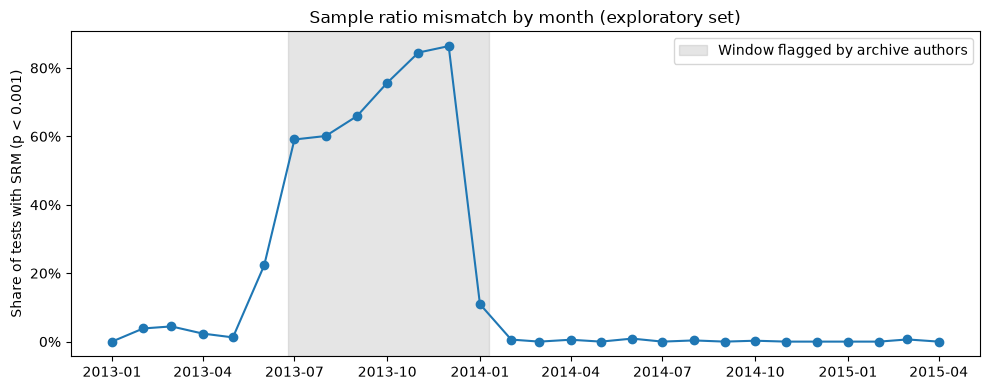

In [86]:
monthly = (
    tests.assign(month=tests["started_at"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(n_tests=("test_id", "size"), srm_rate=("is_srm", "mean"))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(
    pd.Timestamp("2013-06-25"),
    pd.Timestamp("2014-01-10"),
    alpha=0.2,
    color="gray",
    label="Window flagged by archive authors",
)
ax.plot(monthly["month"], monthly["srm_rate"], marker="o")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Share of tests with SRM (p < 0.001)")
ax.set_title("Sample ratio mismatch by month (exploratory set)")
ax.legend()
fig.tight_layout()

Path("../docs/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../docs/figures/srm_by_month.png", dpi=150)
plt.show()

In [87]:
outliers = (
    tests[~tests["is_problem_period"]]
    .sort_values("chi_square_stat", ascending=False)
    .head(10)
)
outliers[["test_id", "started_at", "n_arms", "min_arm_impressions", "max_arm_impressions", "chi_square_stat"]]

,test_id,started_at,n_arms,min_arm_impressions,max_arm_impressions,chi_square_stat
4696,5348bd88fe9c5a1bf500001b,2014-04-12 04:23:04.768,9,1902,25314,105482.183405
1834,51ba8eccf8afde8071004ec1,2013-06-14 03:32:48.535,4,3405,3918,45.107942
3381,51bfb057b3f46d5245002ba5,2013-06-18 00:57:33.577,4,3329,3790,34.400797
4743,53e0f87ee80b542c00000008,2014-08-05 15:31:13.975,6,3729,4076,26.418222
4795,51aebbebd8dd72f1fa001b39,2013-06-05 04:35:31.216,4,3369,3729,26.310265
356,53a310ea8a51fe31fb00005f,2014-06-19 16:33:46.778,6,3401,3712,23.813646
2927,54dd48c7336332001a790000,2015-02-13 00:43:51.068,11,1423,1585,22.016152
3802,5143606b220cb800020005d7,2013-03-09 06:54:43.000,5,2069,2340,21.519255
2593,52d7196274cd933f650038a6,2014-01-15 23:27:48.378,4,2702,2996,21.435144
285,542ddfdb52a3f6b592000074,2014-10-02 23:29:31.552,5,5517,5917,20.649251


In [88]:
top_id = outliers["test_id"].iloc[0]

job_config = bigquery.QueryJobConfig(
    query_parameters=[bigquery.ScalarQueryParameter("test_id", "STRING", top_id)]
)
sql = """
select created_at, impressions, clicks, headline
from `headline-ab-audit.analytics_staging.stg_packages`
where test_id = @test_id
order by created_at
"""
client.query(sql, job_config=job_config).to_dataframe()

c:\dev\headline-ab-audit\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,created_at,impressions,clicks,headline
0,2014-04-12 04:23:04.768000+00:00,1966,47,The Most Honest And Evil Company Ad I Have Eve...
1,2014-04-12 04:35:44.371000+00:00,1902,57,The Most Honest And Evil Company Ad I Have Eve...
2,2014-04-12 04:36:58.205000+00:00,1917,34,The Most Honest And Evil Company Ad I Have Eve...
3,2014-04-12 04:37:07.107000+00:00,2108,62,The Most Honest And Evil Company Ad I Have Eve...
4,2014-04-12 04:37:15.769000+00:00,2026,73,The Most Honest And Evil Company Ad I Have Eve...
5,2014-04-12 04:37:24.787000+00:00,2022,53,The Most Honest And Evil Company Ad I Have Eve...
6,2014-04-12 04:37:34.706000+00:00,25314,975,The Most Honest And Evil Company Ad I Have Eve...
7,2014-04-12 04:37:43.708000+00:00,1992,43,The Most Honest And Evil Company Ad I Have Eve...
8,2014-04-12 04:37:53.288000+00:00,2006,51,The Most Honest And Evil Company Ad I Have Eve...


In [89]:
tests["arms_created_together"] = tests["arm_created_spread_minutes"] <= 60

tests.groupby(["is_problem_period", "arms_created_together"]).agg(
    n_tests=("test_id", "size"),
    srm_rate=("is_srm", "mean"),
)

n_tests  srm_rate
is_problem_period arms_created_together                   
False             False                      197  0.010152
                  True                      3626  0.004413
True              False                       19  0.736842
                  True                      1031  0.699321

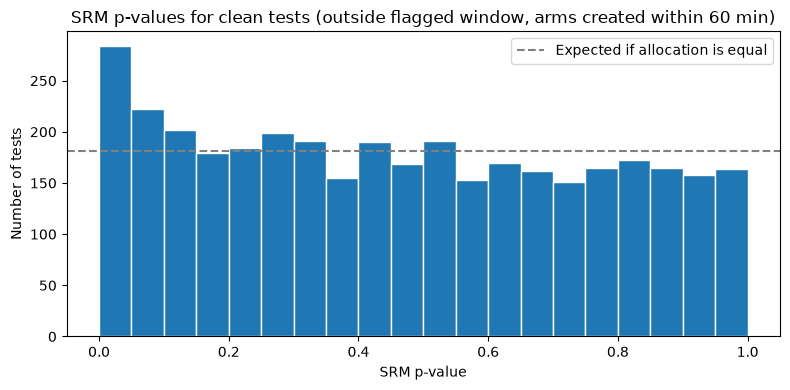

Clean tests: 3626
Share with p < 0.001: 0.44% (expected ~0.1%)


In [90]:
clean = tests[~tests["is_problem_period"] & tests["arms_created_together"]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(clean["p_value"], bins=20, edgecolor="white")
ax.axhline(len(clean) / 20, color="gray", linestyle="--", label="Expected if allocation is equal")
ax.set_xlabel("SRM p-value")
ax.set_ylabel("Number of tests")
ax.set_title("SRM p-values for clean tests (outside flagged window, arms created within 60 min)")
ax.legend()
fig.tight_layout()
fig.savefig("../docs/figures/srm_pvalue_hist_clean.png", dpi=150)
plt.show()

print(f"Clean tests: {len(clean)}")
print(f"Share with p < {ALPHA}: {(clean['p_value'] < ALPHA).mean():.2%} (expected ~{ALPHA:.1%})")

In [91]:
def weekly_srm(start, end):
    subset = tests[(tests["started_at"] >= start) & (tests["started_at"] < end)]
    return subset.assign(week=subset["started_at"].dt.to_period("W").dt.start_time).groupby("week").agg(
        n_tests=("test_id", "size"),
        n_srm=("is_srm", "sum"),
        srm_rate=("is_srm", "mean"),
    )

print("Start of the window")
display(weekly_srm("2013-05-13", "2013-07-15"))
print("End of the window")
display(weekly_srm("2013-12-16", "2014-02-10"))

Start of the window


,n_tests,n_srm,srm_rate
week,,,
2013-05-13,28,1,0.035714
2013-05-20,9,0,0.000000
2013-05-27,16,0,0.000000
2013-06-03,27,1,0.037037
2013-06-10,39,1,0.025641
2013-06-17,32,2,0.062500
2013-06-24,47,29,0.617021
2013-07-01,35,19,0.542857
2013-07-08,37,23,0.621622


End of the window


,n_tests,n_srm,srm_rate
week,,,
2013-12-16,40,35,0.875000
2013-12-23,5,3,0.600000
2013-12-30,17,10,0.588235
2014-01-06,29,10,0.344828
2014-01-13,40,1,0.025000
2014-01-20,31,0,0.000000
2014-01-27,37,0,0.000000
2014-02-03,38,0,0.000000


In [92]:
tests.loc[~tests["is_problem_period"], "arm_created_spread_minutes"].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

count        3823.0
mean      70.210829
std      696.607833
min             0.0
50%             3.0
75%             9.0
90%            26.0
95%            64.0
99%         1313.78
max         21461.0
Name: arm_created_spread_minutes, dtype: Float64

In [93]:
before = clean["started_at"] < "2013-06-25"

for label, subset in [("Before window", clean[before]), ("After window", clean[~before])]:
    print(
        f"{label}: {len(subset)} tests, "
        f"p < 0.001: {(subset['p_value'] < ALPHA).mean():.2%}, "
        f"p < 0.05: {(subset['p_value'] < 0.05).mean():.1%} (expected 5.0%)"
    )

Before window: 341 tests, p < 0.001: 2.93%, p < 0.05: 19.4% (expected 5.0%)
After window: 3285 tests, p < 0.001: 0.18%, p < 0.05: 6.6% (expected 5.0%)


## Q1 findings

1. **The SRM check independently recovers the window flagged by the archive authors.**
   Using a chi-square test at p < 0.001, 70.0% of tests in the flagged window
   (2013-06-25 to 2014-01-10) show sample ratio mismatch, versus 0.47% outside it.
   97.6% of all SRM-flagged tests fall inside the window.

2. **The window boundaries match at weekly resolution.**
   The SRM rate jumps from 6% to 62% in the week of 2013-06-24 and drops from 34% to 2.5%
   in the week of 2014-01-13. A monthly view alone suggested an earlier start,
   because the last week of June 2013 pulled up the June average.

3. **Arms added after a test started explain little of the SRM outside the window.**
   Half of the tests create all arms within 3 minutes and 95% within 64 minutes,
   so arms created more than 60 minutes apart are treated as added later.
   Only 2 of the 18 SRM-flagged tests outside the window fall in that group.
   The single most extreme test (chi-square 105,482) had all 9 arms created within
   14 minutes; one arm received 12 times the impressions of the others.
   The cause cannot be determined from the data.

4. **The equal-allocation assumption holds after the window; tests before it show mild imbalance.**
   For 3,626 clean tests (outside the window, arms created within 60 minutes),
   SRM p-values are close to uniform above 0.15, but the lowest bin is about
   1.6 times the expected count. The excess comes from the 341 clean tests started
   before the window: 19.4% have p < 0.05 (5% expected) and 2.93% have p < 0.001.
   The 3,285 clean tests started after the window are close to expectation
   (6.6% with p < 0.05, 0.18% with p < 0.001).

**Decision for downstream analysis (Q2, Q3):**
- Exclude tests in the flagged window and any test with SRM at p < 0.001.
- Use tests started after the window (from 2014-01-11) as the primary sample,
  where randomization looks reliable.
- Use tests started before the window only as a sensitivity check.